# Stabilizing each mite on its own

**The proposal:** `PlateStabilizer` now measures every mite's shift in each frame, takes the median over all mites as the plate's shift, and moves every mite's patch back by that one shift. `plate_shake.ipynb` showed that the zones can move separately (at 1.3 h in the long run they moved by 0.1 to 0.85 px). The proposal is to move each mite's patch back by **its own** measured shift instead. The mites are glued down, so a mite's body should only move with what it is glued to.

**The risk:** a mite that comes unglued and walks or turns moves its body. Its own shift then follows that movement, and stabilizing on it would cancel the very movement the score should see. Those mites need a flag for the user to review.

**This report** (no code changed yet):

1. the trace of each mite's centre across recordings and within a recording, for the mites that move most and least;
2. how far a mite's own shift strays from the plate's within a recording, for mites labelled still and moving;
3. the movement score with no stabilization, the plate's shift and each mite's own shift;
4. a rule to flag the mites that come unglued.

A mite's **centre** is the centre of its box moved by its measured shift: the shift of its patch (box plus 8 px) from a reference, by phase correlation refined by ECC, as `PlateStabilizer` measures it. Across recordings the reference is the mite's mean image in recording 1; within a recording it is the recording's first frame. ECC also returns a **match**, the correlation of the two patches after the shift (1 = identical). It drops when the mite's image changes, not only when it shifts.

**On the labels:** the long run's labels were saved equal to `outline_variability >= 0.31` with the plate's stabilization. Scored against them, the plate's method agrees by construction. The methods are compared on the three short datasets, whose labels are by hand, and on the long run only by what does not depend on that: dead mites (500 min or more after their last labelled movement) called moving, and how many calls change.

## Findings

These numbers come from the run saved in this notebook (14 October 2026): the four datasets in `calibration_data/`, 145 mites, mainly the long run (59 mites, 295 recordings, 49 hours). The score is `outline_variability` at 0.31.

**The traces**

- **Most mites stay glued.** The 4 least movers stay within about 0.1 px of their zone's median for the whole run: their traces sit inside the cloud of their zone's. The only big step in every trace is the zones' own jump at 1.3 h (see `plate_shake.ipynb`).
- **One mite came unglued: mite 40 turned.** Between 1 and 5 hours it turned by about 60° in place; the pictures show it lying vertical at the start and horizontal from about 4 h on. Its centre moved by only 0.6 px. Its image no longer matches recording 1, so registering it against recording 1 fails now and then from 20 h on (10 to 900 px, points off its panel).
- **Mite 11 crept by about 1 px from its zone** while alive (up to 23.5 h), then stayed there. That is under the limit and not flagged. Mites 59 and 29 crept by 0.4 px.

**Within a recording, each mite's own shift against the plate's**

- **For a still mite, its own shift is the plate's.** It strays by 0.03 px in the middle, up to 0.06 px. That is the measurement's noise, in every dataset.
- **A moving mite's legs pull its own shift by 0.07 to 0.11 px in the middle, up to 0.26 px.** Stabilizing on its own shift moves part of its movement out of the patch.
- **The score hardly changes.** With its own shift, a mite's score is 0.996 of its score with the plate's shift (in the middle; 95% are above 0.97). In the long run the calls are the same in all but 2 of about 17,400 mite-recordings, both with scores at the threshold (0.30 to 0.32). Dead mites called moving: 0% with either method (0.44% with no stabilization). The three short datasets cannot tell the methods apart: their shake is 0.01 px, and even no stabilization gets the same AUC (1.0) and accuracy (0.998).
- **A neighbour can pull a mite's own shift a long way.** Mite 1 at 4.5 h: a mite walking by moves into its patch, and mite 1's own shift follows it by 2.95 px, while mite 1 does not move. Stabilizing on that shift would move mite 1's patch by 3 px.

**The flags**

- **Within a recording: the own shift strays more than 0.3 px from the plate's.** That is above anything a glued moving mite reaches (0.26 px). In that recording the patch falls back to the plate's shift. It fires on 3 of 17,921 mite-recordings: mites 1, 41 and 49 of the long run, once each, all in zone 6 between 4.0 and 4.5 h. **The mover is the detection marked *not a mite* (12).** It starts in its box in zone 3 and walks off at 1 h. It rests at the edge of zone 3 until 3.7 h, then crosses into zone 6 and passes mites 49, 41, 55, 1 and 58 between 4.0 and 4.7 h. It gets within reach of each flagged mite in the recording it was flagged. So the zones do not keep a walking mite in, and a detection marked *not a mite* is left out of the scores but still walks through other mites' patches.
- **Across recordings: the mite turned by more than 30°** (smoothed over 5 recordings) **or sits more than 1.5 px from its zone's median, in 3 recordings or more.** It flags only mite 40: it turned, from 2.3 h on. Without the turn the flag would come only at 20 h, when its registration starts failing. The other dead mites turn by 2° in the middle and 22° at most, under the limit.
- 4 mites of 145 are flagged in all; none in the short datasets.

**What it means**

- Per-mite stabilization with these flags is safe on these datasets. With the fallback, the only case where it would have gone wrong (mite 1) is covered, and it changes 2 calls at the threshold.
- **It also gains nothing measurable here.** Within a recording the plate shakes as one piece; the zones only moved apart between recordings, and the movement score never compares recordings. Where each mite's (or each zone's) own shift does matter is between recordings: `RecordingChange`, and the drift that the turn and zone flags look at.
- The flags are worth having whichever method is used. Mite 40 turned in place within the first 5 hours, and nothing in the app notices that now.

In [1]:
import hashlib
import inspect
import pickle
import sys
import tempfile
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT)]

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap

import pipeline
from classes import calibration, plate_stabilizer
from classes.analyzer import Analyzer
from classes.app_config import get_default_config
from classes.data_loader import DataLoader
from classes.plate_stabilizer import PlateStabilizer, _ECC_CRITERIA, _gray, _patches
from classes.workers import side_by_side

# The project's reporting module switches matplotlib to Agg (no figures) on import.
%matplotlib inline

MARGIN = 8                                   # pixels around each box the shifts are measured with
REACH = MARGIN + pipeline.STABILIZE_MARGIN   # how far past the boxes the frames are read
DEATH_MINUTES = 500                          # a mite still this long after its last movement is taken as dead
config = get_default_config().mite
METRIC, PARAMS = config.metric, config.params_for(config.metric)
THRESHOLD = config.threshold_for(METRIC)
PAD = Analyzer.roi_padding(METRIC, PARAMS)
METHODS = {"none": "no stabilization", "plate": "plate's shift (now)", "mite": "each mite's own shift"}
CACHE = Path(tempfile.gettempdir()) / "varroa_per_mite_stabilization"

# Chart style, as in the other notebooks: thin marks, recessive axes and grid, text in ink colours.
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8d8c85"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3dc"
COLORS = {"none": GREY, "plate": BLUE, "mite": ORANGE}
TIME = LinearSegmentedColormap.from_list("time", ["#c9dcf3", BLUE, "#0d2f5e"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "legend.frameon": False, "legend.fontsize": 8.5, "lines.linewidth": 2,
})
pd.set_option("display.precision", 3)
print(f"movement score: {METRIC} {PARAMS}, threshold {THRESHOLD:g}")

movement score: outline_variability {'relative': 0.0, 'width': 1.5, 'pad': 16}, threshold 0.31


## Measuring every recording

Per dataset and recording: every detection's shift in every frame and its match, the plate's shift (median over the detections), and the movement score of each mite three ways (patch not moved, moved back by the plate's shift, moved back by its own). Each mite's image in a recording (mean of its frames, moved back by the plate's shift) is then registered against recording 1. This reads every recording once (a few minutes). The results are kept in the system's temporary folder, keyed by the stabilizer's and the scoring code, so a second run starts at once.

In [2]:
def register(reference, moved, window):
    # (dx, dy, match): PlateStabilizer._shift, with ECC's correlation kept (nan where ECC gave up)
    (dx, dy), _ = cv2.phaseCorrelate(reference.copy(), moved.copy(), window)
    warp = np.float32([[1, 0, dx], [0, 1, dy]])
    try:
        match, warp = cv2.findTransformECC(reference, moved, warp, cv2.MOTION_TRANSLATION, _ECC_CRITERIA, None, 1)
    except cv2.error:
        match = np.nan
    return float(warp[0, 2]), float(warp[1, 2]), float(match)


def measure(dataset_id):
    data = pipeline._read_dataset(dataset_id, pipeline.CALIBRATION_LIBRARY)
    recordings_dir = pipeline._recordings_dir(data["data_dir"], pipeline.CALIBRATION_LIBRARY)
    if not recordings_dir.is_dir():
        recordings_dir = pipeline._dataset_dir(dataset_id, pipeline.CALIBRATION_LIBRARY) / pipeline.RECORDINGS_DIRNAME
    times = np.array(data["times"], dtype=float)
    states = {mite["id"]: calibration.per_recording(data["truth"].get(mite["id"]), len(times)) for mite in data["mites"]}
    boxes = pipeline.mite_boxes(data["mites"])
    ids = list(boxes)
    x0, y0 = min(b[0] for b in boxes.values()) - REACH, min(b[1] for b in boxes.values()) - REACH
    x_end, y_end = max(b[2] for b in boxes.values()) + REACH, max(b[3] for b in boxes.values()) + REACH
    local = [(x1 - x0, y1 - y0, x2 - x0, y2 - y0) for x1, y1, x2, y2 in boxes.values()]
    loader = DataLoader(recordings_dir, grayscale=False)

    def frame_shifts(frames, box):
        patches = _gray(_patches(frames, box[0] - MARGIN, box[1] - MARGIN, box[2] + MARGIN, box[3] + MARGIN))
        window = cv2.createHanningWindow(patches.shape[:0:-1], cv2.CV_32F)
        return [register(patches[0], patch, window) for patch in patches]

    within, scores, images = [], [], []
    for recording in data["recordings"]:
        frames = loader.load_recording_region(recording["name"], x0, y0, x_end, y_end)
        found = np.array(side_by_side(lambda box: frame_shifts(frames, box), local))   # (mites, frames, 3)
        own = found[..., :2]
        plate = np.median(own, axis=0)
        within.append(found)
        shifts = {"none": [np.zeros_like(plate)] * len(local), "plate": [plate] * len(local), "mite": list(own)}
        scores.append({method: side_by_side(lambda job: Analyzer._motion_score(
            PlateStabilizer.cut(frames, job[0], PAD, job[1]), METRIC, PARAMS), list(zip(local, per_mite)))
            for method, per_mite in shifts.items()})
        images.append([PlateStabilizer.cut(frames, box, MARGIN, plate).mean(axis=(0, 3)) for box in local])

    def across_one(mite):
        window = cv2.createHanningWindow(images[0][mite].shape[::-1], cv2.CV_32F)
        return [register(images[0][mite], images[r][mite], window) for r in range(len(images))]

    across = np.array(side_by_side(across_one, range(len(ids))))                       # (mites, recordings, 3)
    labels = np.array([states[i] for i in ids], dtype=object)
    zone_of = {mite["id"]: mite["zone_id"] for mite in data["mites"]}
    return {"name": data["name"], "times": times, "ids": ids,
            "kept": np.array([not calibration.is_rejected(states[i]) for i in ids]),
            "zones": np.array([zone_of[i] for i in ids]),
            "centres": np.array([((b[0] + b[2]) / 2, (b[1] + b[3]) / 2) for b in boxes.values()]),
            "moving": labels == calibration.MOVING, "still": labels == calibration.STILL,
            "within": np.array(within).transpose(1, 0, 2, 3),                              # (mites, recordings, frames, 3)
            "scores": {m: np.array([s[m] for s in scores]).T for m in METHODS},            # (mites, recordings)
            "across": across,
            "images": [np.array([images[r][m] for r in range(len(images))]) for m in range(len(ids))]}  # per mite (recordings, h, w)


version = hashlib.sha1((inspect.getsource(plate_stabilizer) + inspect.getsource(Analyzer) + inspect.getsource(measure)
                        + inspect.getsource(register) + repr((MARGIN, METRIC, PARAMS))).encode()).hexdigest()[:12]
runs = {}
CACHE.mkdir(exist_ok=True)
for summary in sorted(pipeline.list_calibration_datasets(), key=lambda s: s["id"]):
    path = CACHE / f"{summary['id']}-{version}.pkl"
    if path.is_file():
        run = pickle.loads(path.read_bytes())
    else:
        run = measure(summary["id"])
        path.write_bytes(pickle.dumps(run))
    runs[run["name"]] = run
    print(f"{run['name']}: {run['kept'].sum()} mites, {len(run['times'])} recordings, {run['within'].shape[2]} frames each")
LONG = max(runs, key=lambda name: len(runs[name]["times"]))
SHORT = [name for name in runs if name != LONG]

ground_truth_60min: 29 mites, 6 recordings, 30 frames each
ground_truth_90min: 28 mites, 6 recordings, 30 frames each
sample_data: 29 mites, 6 recordings, 30 frames each
test_run_2026-09-08_Mathis_last_dsRNA: 59 mites, 295 recordings, 10 frames each


## 1. The mite centre as a trace

### Across recordings

Each mite's centre, recording by recording, relative to where it was in recording 1. The colour runs from light (start) to dark (end of the run). The dashed grey line is the median of the mite's zone: what the zone it is glued in did. A glued mite follows its zone; a mite that comes unglued leaves it.

The mites are ranked by how far they move **away from their zone**: the 95th percentile, over the recordings, of the distance between the mite's displacement and its zone's (the 95th percentile, not the largest, so one bad registration does not rank a mite).

mite,zone,"away from its zone, 95% (px)",largest (px),median match,recordings labelled moving
40,6,36.61,887.09,0.89,25
11,7,1.05,1.08,0.98,17
59,9,0.41,0.55,0.88,2
29,7,0.41,0.44,0.93,22
50,7,0.36,0.37,0.98,14
56,7,0.31,0.33,0.99,23
49,6,0.31,0.70,0.94,10
42,7,0.30,0.34,0.94,40


the least:


mite,zone,"away from its zone, 95% (px)",largest (px),median match,recordings labelled moving
43,3,0.07,0.12,0.98,27
37,4,0.06,0.10,0.98,19
38,10,0.05,0.06,0.98,12
44,4,0.04,0.10,0.97,7


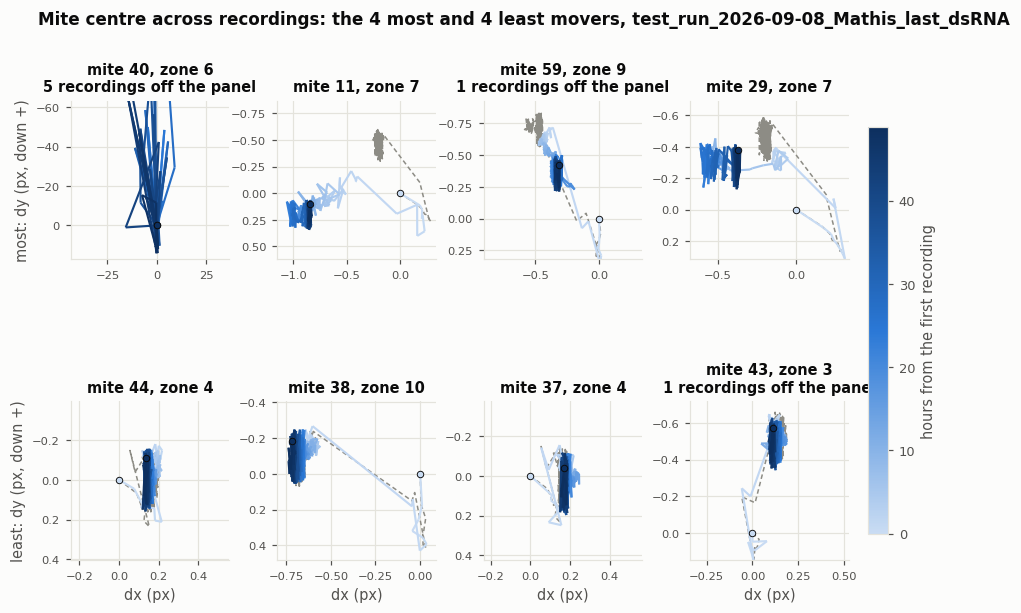

In [3]:
run = runs[LONG]
kept = np.flatnonzero(run["kept"])
hours = run["times"] / 60
across = run["across"][..., :2]                                        # (mites, recordings, 2)
zone_drift = {z: np.median(across[kept[run["zones"][kept] == z]], axis=0) for z in set(run["zones"][kept])}
own_drift = np.array([across[m] - zone_drift.get(run["zones"][m], 0) for m in range(len(run["ids"]))])
away = np.percentile(np.hypot(own_drift[..., 0], own_drift[..., 1]), 95, axis=1)
ranked = kept[np.argsort(away[kept])]
most, least = ranked[::-1][:4], ranked[:4]
moved_ever = run["moving"].any(axis=1)

table = pd.DataFrame({"mite": [run["ids"][m] for m in ranked[::-1]], "zone": run["zones"][ranked[::-1]],
                      "away from its zone, 95% (px)": away[ranked[::-1]],
                      "largest (px)": np.hypot(own_drift[ranked[::-1], :, 0], own_drift[ranked[::-1], :, 1]).max(axis=1),
                      "median match": np.nanmedian(run["across"][ranked[::-1], :, 2], axis=1),
                      "recordings labelled moving": run["moving"][ranked[::-1]].sum(axis=1)})
display(table.head(8).style.format(precision=2).hide(axis="index"))
print("the least:")
display(table.tail(4).style.format(precision=2).hide(axis="index"))


def trace(ax, xy, colour_by, cmap=TIME, linewidth=1.4):
    segments = np.stack([xy[:-1], xy[1:]], axis=1)
    lines = LineCollection(segments, cmap=cmap, linewidth=linewidth)
    lines.set_array(colour_by[:-1])
    ax.add_collection(lines)
    ax.scatter(*xy[0], s=18, color="#c9dcf3", edgecolor=INK, linewidth=0.6, zorder=3)
    ax.scatter(*xy[-1], s=18, color="#0d2f5e", edgecolor=INK, linewidth=0.6, zorder=3)
    return lines


def trace_grid(title):
    fig, axes = plt.subplots(2, 4, figsize=(11, 6), gridspec_kw={"hspace": 0.45, "wspace": 0.3})
    for row, (group, label) in enumerate(((most, "most"), (least, "least"))):
        for ax, m in zip(axes[row], group):
            zone = zone_drift[run["zones"][m]]
            # the panel holds 98% of the trace: a registration that failed (far off) is left outside and counted
            low, high = np.percentile(np.concatenate([across[m], zone]), [1, 99], axis=0)
            half = max(0.6 * (high - low).max(), 0.4)
            centre = (low + high) / 2
            outside = int((np.abs(across[m] - centre) > half).any(axis=1).sum())
            ax.plot(*zone.T, color=GREY, linewidth=1, linestyle=(0, (3, 2)))
            lines = trace(ax, across[m], hours)
            ax.set(xlim=(centre[0] - half, centre[0] + half), ylim=(centre[1] + half, centre[1] - half), aspect="equal")
            ax.set_title(f"mite {run['ids'][m]}, zone {run['zones'][m]}" + ("" if moved_ever[m] else ", never moved")
                         + (f"\n{outside} recordings off the panel" if outside else ""), fontsize=9.5)
            ax.tick_params(labelsize=7.5)
        axes[row, 0].set_ylabel(f"{label}: dy (px, down +)")
    for ax in axes[1]:
        ax.set_xlabel("dx (px)")
    fig.colorbar(lines, ax=axes, pad=0.02, shrink=0.8, label="hours from the first recording")
    fig.suptitle(title, fontsize=11, fontweight="bold", color=INK, y=0.98)
    plt.show()


trace_grid(f"Mite centre across recordings: the 4 most and 4 least movers, {LONG}")

### Within a recording

The same mites, frame by frame, in the shakiest recording of the long run and in one recording where each of them was labelled moving (if it ever was). Dashed grey: the plate's shift, the median over all detections. This is what each method would move the patch back by: the dashed line for the plate's method, the coloured one for each mite's own.

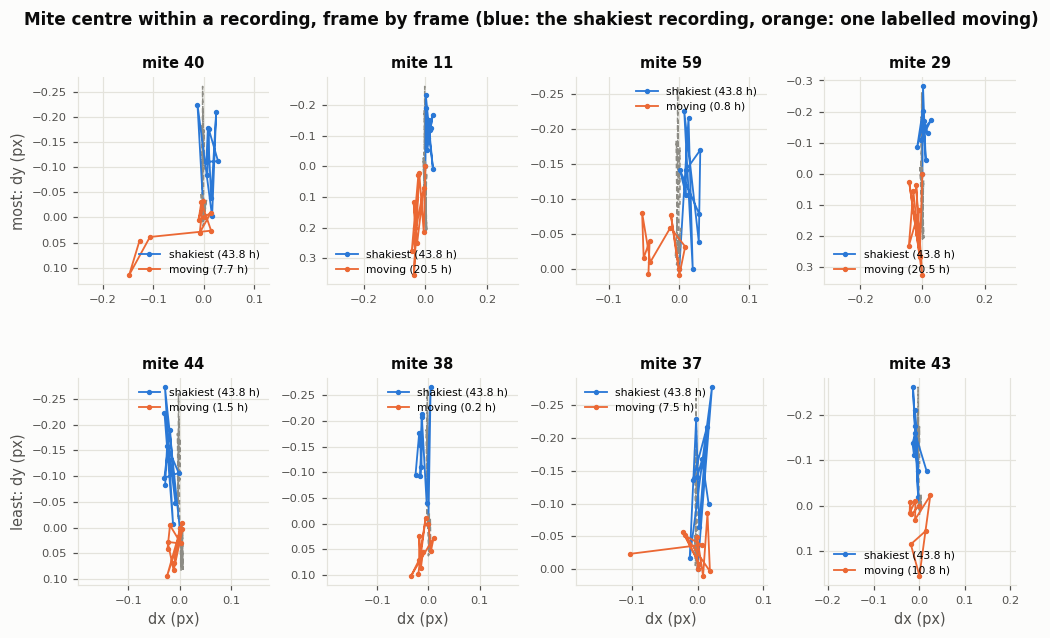

In [4]:
plate_within = np.median(run["within"][..., :2], axis=0)                       # (recordings, frames, 2)
shake = np.hypot(plate_within[..., 0], plate_within[..., 1]).max(axis=1)
shakiest = int(np.argmax(shake))
frames_index = np.arange(run["within"].shape[2])

fig, axes = plt.subplots(2, 4, figsize=(11, 6), gridspec_kw={"hspace": 0.45, "wspace": 0.3})
for ax, m in zip(axes.flat, list(most) + list(least)):
    moving_at = np.flatnonzero(run["moving"][m])
    at = int(moving_at[np.argmax(np.hypot(*run["within"][m, moving_at, :, :2].transpose(2, 0, 1)).max(axis=1))]) \
        if len(moving_at) else shakiest
    for recording, style in ((shakiest, "shakiest"), (at, "moving")):
        if style == "moving" and not len(moving_at):
            continue
        xy = run["within"][m, recording, :, :2]
        ax.plot(*plate_within[recording].T, color=GREY, linewidth=1, linestyle=(0, (3, 2)))
        ax.plot(*xy.T, color=BLUE if style == "shakiest" else ORANGE, linewidth=1.2, marker="o", markersize=2.5,
                label=f"{style} ({hours[recording]:.1f} h)")
    ax.set_title(f"mite {run['ids'][m]}", fontsize=9.5)
    ax.set_aspect("equal", adjustable="datalim")
    ax.invert_yaxis()
    ax.tick_params(labelsize=7.5)
    ax.legend(loc="best", fontsize=7)
axes[0, 0].set_ylabel("most: dy (px)")
axes[1, 0].set_ylabel("least: dy (px)")
for ax in axes[1]:
    ax.set_xlabel("dx (px)")
fig.suptitle("Mite centre within a recording, frame by frame (blue: the shakiest recording, orange: one labelled moving)",
             fontsize=11, fontweight="bold", color=INK, y=0.98)
plt.show()

## 2. How far a mite strays from the plate within a recording

Per mite and recording: the largest distance, over the frames, between the mite's own shift and the plate's. This is the difference between the two methods: what per-mite stabilization moves the patch back by that the plate's method does not. If it is small for still mites, per-mite stabilization changes nothing for them. If it is large for moving mites, it would cancel part of their movement. Short datasets: labels by hand. Long run: labels equal the score's calls.

dataset,label,n,stray: median (px),95%,99%,largest,worst-frame match: median,1%
ground_truth_60min,still,96,0.034,0.044,0.047,0.056,0.997,0.996
ground_truth_60min,moving,78,0.108,0.216,0.253,0.261,0.989,0.966
ground_truth_90min,still,97,0.033,0.043,0.058,0.059,0.997,0.995
ground_truth_90min,moving,71,0.112,0.208,0.240,0.252,0.989,0.970
sample_data,still,97,0.034,0.043,0.054,0.062,0.997,0.996
sample_data,moving,76,0.111,0.188,0.243,0.248,0.989,0.971
test_run_2026-09-08_Mathis_last_dsRNA,still,16471,0.032,0.044,0.051,0.088,0.990,0.966
test_run_2026-09-08_Mathis_last_dsRNA,moving,843,0.068,0.145,0.181,0.224,0.990,0.970


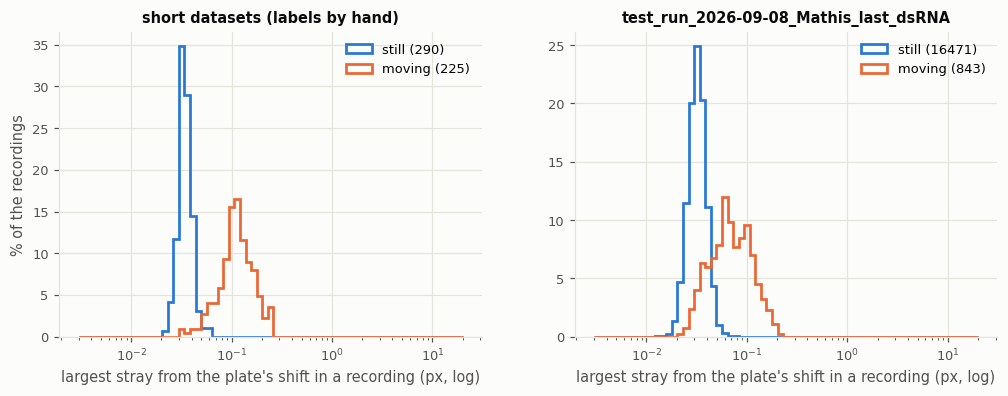

In [5]:
def strays(run):
    own = run["within"][..., :2]
    plate = np.median(own, axis=0)
    return np.hypot(*(own - plate).transpose(3, 0, 1, 2)).max(axis=2)        # (mites, recordings)


rows = []
for name, run in runs.items():
    stray = strays(run)
    run["stray"] = stray
    match = np.nanmin(run["within"][..., 2], axis=2)                          # worst frame's match
    run["frame_match"] = match
    for label, mask in (("still", run["still"]), ("moving", run["moving"])):
        mask = mask & run["kept"][:, None]
        rows.append({"dataset": name, "label": label, "n": int(mask.sum()), "stray: median (px)": np.median(stray[mask]),
                     "95%": np.percentile(stray[mask], 95), "99%": np.percentile(stray[mask], 99),
                     "largest": stray[mask].max(), "worst-frame match: median": np.median(match[mask]),
                     "1%": np.percentile(match[mask], 1)})
display(pd.DataFrame(rows).style.format({"n": "{:.0f}"}, precision=3).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False, gridspec_kw={"wspace": 0.22})
bins = np.geomspace(0.003, 20, 70)
for ax, names, title in ((axes[0], SHORT, "short datasets (labels by hand)"), (axes[1], [LONG], LONG)):
    for label, colour in (("still", BLUE), ("moving", ORANGE)):
        values = np.concatenate([runs[n]["stray"][runs[n][label] & runs[n]["kept"][:, None]] for n in names])
        ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)), histtype="step", linewidth=1.8,
                color=colour, label=f"{label} ({len(values)})")
    ax.set_xscale("log")
    ax.set(xlabel="largest stray from the plate's shift in a recording (px, log)", title=title)
    ax.title.set_fontsize(9.5)
    ax.legend()
axes[0].set_ylabel("% of the recordings")
plt.show()

## 3. The movement score, three ways

Each mite's score in each recording: the patch not moved, moved back by the plate's shift (now) and moved back by its own shift (the proposal). The short datasets are scored against their labels: AUC, and the calls at the threshold in use (0.31, calibrated with the plate's method) and at each method's own best threshold (Youden's J). The long run is scored without its labels: dead mites called moving, and how many calls change from the plate's method.

In [6]:
rows = []
for method in METHODS:
    score = np.concatenate([runs[n]["scores"][method][(runs[n]["moving"] | runs[n]["still"]) & runs[n]["kept"][:, None]]
                            for n in SHORT])
    truth = np.concatenate([runs[n]["moving"][(runs[n]["moving"] | runs[n]["still"]) & runs[n]["kept"][:, None]]
                            for n in SHORT])
    at = calibration.confusion(score, truth, THRESHOLD)
    best = calibration.best_threshold(score, truth)
    at_best = calibration.confusion(score, truth, best)
    rows.append({"stabilization": METHODS[method], "AUC": calibration.auc(score, truth),
                 f"accuracy at {THRESHOLD:g}": at["accuracy"], "still called moving": at["still_called_moving"],
                 "moving called still": at["moving_called_still"], "own best threshold": best,
                 "accuracy there": at_best["accuracy"]})
print(f"short datasets: {len(truth)} labelled mite-recordings, {truth.sum()} moving")
display(pd.DataFrame(rows).style.format(precision=3).hide(axis="index"))

short datasets: 515 labelled mite-recordings, 225 moving


stabilization,AUC,accuracy at 0.31,still called moving,moving called still,own best threshold,accuracy there
no stabilization,1.000,0.998,1,0,0.307,0.998
plate's shift (now),1.000,0.998,1,0,0.307,0.998
each mite's own shift,1.000,0.998,1,0,0.311,0.998


test_run_2026-09-08_Mathis_last_dsRNA: 10206 dead mite-recordings, 3822 alive (up to the last movement)


stabilization,dead: score median,dead: 99%,dead called moving,alive: called moving,"calls moving, all",changed from the plate's
no stabilization,0.054,0.264,0.44%,22.3%,913,49
plate's shift (now),0.038,0.133,0.00%,22.2%,864,0
each mite's own shift,0.038,0.134,0.00%,22.2%,864,2


recordings the plate's method calls moving: 864; per-mite stabilization keeps 863, loses 1 (in 1 mites), adds 1
their score, own shift / plate's shift: median 0.996, 5% below 0.970


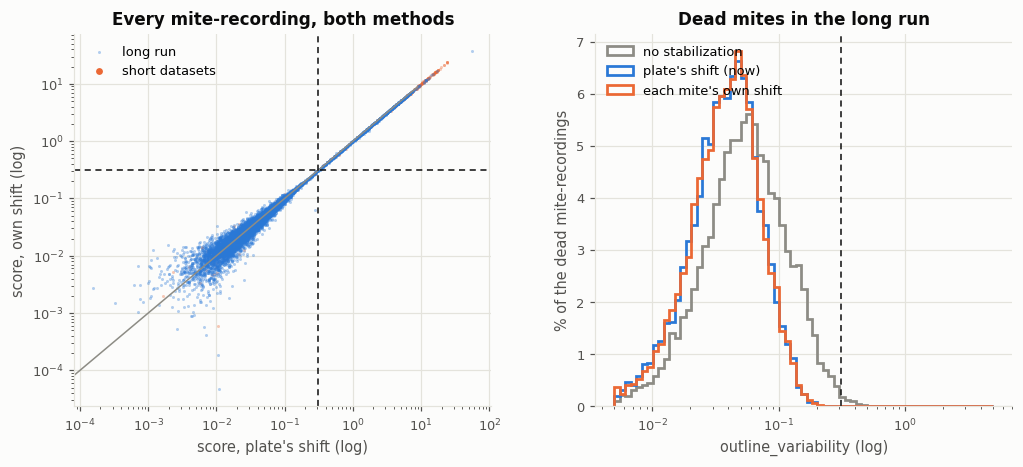

In [7]:
run = runs[LONG]
kept = run["kept"]
moving = run["moving"]
moved = moving.any(axis=1)
last = np.where(moved, moving.shape[1] - 1 - np.argmax(moving[:, ::-1], axis=1), 0)
dead = moved[:, None] & (run["times"][None] - run["times"][last][:, None] >= DEATH_MINUTES) & kept[:, None]
alive = moved[:, None] & (np.arange(moving.shape[1])[None] <= last[:, None]) & kept[:, None]
called = {m: run["scores"][m] > THRESHOLD for m in METHODS}

rows = []
for method in METHODS:
    score = run["scores"][method]
    rows.append({"stabilization": METHODS[method], "dead: score median": np.median(score[dead]),
                 "dead: 99%": np.percentile(score[dead], 99), "dead called moving": called[method][dead].mean(),
                 "alive: called moving": called[method][alive].mean(),
                 "calls moving, all": int(called[method][kept].sum()),
                 "changed from the plate's": int((called[method] != called["plate"])[kept].sum())})
print(f"{LONG}: {dead.sum()} dead mite-recordings, {alive.sum()} alive (up to the last movement)")
display(pd.DataFrame(rows).style.format({"dead called moving": "{:.2%}", "alive: called moving": "{:.1%}"},
                                        precision=3).hide(axis="index"))

lost = called["plate"] & ~called["mite"] & kept[:, None]
gained = ~called["plate"] & called["mite"] & kept[:, None]
ratio = run["scores"]["mite"][called["plate"] & kept[:, None]] / run["scores"]["plate"][called["plate"] & kept[:, None]]
print(f"recordings the plate's method calls moving: {called['plate'][kept].sum()}; per-mite stabilization keeps "
      f"{(called['plate'] & called['mite'])[kept].sum()}, loses {lost.sum()} (in {lost.any(axis=1).sum()} mites), "
      f"adds {gained.sum()}")
print(f"their score, own shift / plate's shift: median {np.median(ratio):.3f}, 5% below {np.percentile(ratio, 5):.3f}")

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"wspace": 0.25})
for name, marker in [(n, "o") for n in runs]:
    r = runs[name]
    mask = r["kept"][:, None] & np.ones_like(r["moving"])
    ax.scatter(r["scores"]["plate"][mask], r["scores"]["mite"][mask], s=4, color=BLUE if name == LONG else ORANGE,
               alpha=0.35, linewidth=0, label=("long run" if name == LONG else None))
ax.scatter([], [], s=12, color=ORANGE, label="short datasets")
top = max(1, np.percentile(run["scores"]["plate"][kept], 99.9))
ax.plot([0, top], [0, top], color=GREY, linewidth=1)
ax.axvline(THRESHOLD, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax.axhline(THRESHOLD, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax.set(xscale="log", yscale="log", xlabel="score, plate's shift (log)", ylabel="score, own shift (log)",
       title="Every mite-recording, both methods")
ax.legend(loc="upper left")
bins = np.geomspace(0.005, 5, 70)
for method in METHODS:
    values = run["scores"][method][dead]
    ax2.hist(values, bins=bins, histtype="step", linewidth=1.8, color=COLORS[method], label=METHODS[method],
             weights=np.full(len(values), 100 / len(values)))
ax2.axvline(THRESHOLD, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax2.set(xscale="log", xlabel=f"{METRIC} (log)", ylabel="% of the dead mite-recordings",
        title="Dead mites in the long run")
ax2.legend(loc="upper left")
plt.show()

### Where the two methods disagree

The recordings whose call changes from the plate's method to each mite's own shift, and the mite's stray there.

In [8]:
rows = []
for name, r in runs.items():
    plate_call = r["scores"]["plate"] > THRESHOLD
    mite_call = r["scores"]["mite"] > THRESHOLD
    for m, at in zip(*np.nonzero((plate_call != mite_call) & r["kept"][:, None])):
        rows.append({"dataset": name, "mite": r["ids"][m], "hours": r["times"][at] / 60,
                     "labelled": "moving" if r["moving"][m, at] else "still" if r["still"][m, at] else "-",
                     "score, plate": r["scores"]["plate"][m, at], "score, own": r["scores"]["mite"][m, at],
                     "stray (px)": r["stray"][m, at], "worst-frame match": r["frame_match"][m, at]})
display(pd.DataFrame(rows).style.format(precision=2).hide(axis="index"))

dataset,mite,hours,labelled,"score, plate","score, own",stray (px),worst-frame match
test_run_2026-09-08_Mathis_last_dsRNA,48,11.00,still,0.31,0.30,0.04,1.00
test_run_2026-09-08_Mathis_last_dsRNA,52,7.33,still,0.31,0.32,0.03,0.99


## 4. Flagging the mites that come unglued

What the traces show (section 1 and the pictures below) gives two cases in which a mite's own shift is not the shift of what it is glued to:

- **Something else moves in its patch.** A mite walking by (here, the detection marked *not a mite*) pulls the registration along. Within a recording the mite's own shift then strays far from the plate's, further than the legs of a moving glued mite ever pull it. Section 2: moving mites stray up to about 0.25 px, still ones 0.06 px.
- **The mite comes unglued: it turns or slides.** If it slides, it leaves its zone across recordings. If it turns in place, its centre hardly moves, but its body's orientation changes, and its image no longer matches recording 1, so the registration fails now and then (the points off the panel in section 1).

The proposed rules:

- **within a recording:** the own shift strays more than `STRAY_LIMIT` from the plate's. The patch is then moved back by the plate's shift (the own shift is not to be trusted), and the recording is flagged.
- **across recordings:** the mite sits more than `AWAY_LIMIT` from its zone's median in at least `AWAY_COUNT` recordings. The mite is flagged once for review.

In [9]:
moving_strays = np.concatenate([r["stray"][r["moving"] & r["kept"][:, None]] for r in runs.values()])
still_strays = np.concatenate([runs[LONG]["stray"][dead]] +
                              [runs[n]["stray"][runs[n]["still"] & runs[n]["kept"][:, None]] for n in SHORT])
STRAY_LIMIT = 0.3   # above the legs of any moving glued mite
AWAY_LIMIT = 1.5    # px from the zone's median
AWAY_COUNT = 3      # recordings, so that one failed registration flags nothing
print(f"within a recording: still glued mites stray up to {np.percentile(still_strays, 99.9):.3f} px (99.9%), "
      f"moving ones up to {moving_strays.max():.2f} px (largest of {len(moving_strays)}); limit {STRAY_LIMIT:g} px")
dead_away = np.hypot(own_drift[..., 0], own_drift[..., 1])
per_mite = sorted(((dead_away[m][dead[m]].max(), run["ids"][m]) for m in np.flatnonzero(dead.any(axis=1))), reverse=True)
print("across recordings, the dead mites furthest from their zone (largest over their dead recordings): "
      + ", ".join(f"mite {i} {v:.2f} px" for v, i in per_mite[:6]) + f"; limit {AWAY_LIMIT:g} px in {AWAY_COUNT} recordings")


def away_from_zone(r):
    acr = r["across"][..., :2]
    zd = {z: np.median(acr[r["kept"] & (r["zones"] == z)], axis=0) for z in set(r["zones"][r["kept"]])}
    od = np.array([acr[m] - zd.get(r["zones"][m], 0) for m in range(len(r["ids"]))])
    return np.hypot(od[..., 0], od[..., 1])


rows = []
for name, r in runs.items():
    k = r["kept"]
    r["away"] = away_from_zone(r)
    r["flag_within"] = (r["stray"] > STRAY_LIMIT) & k[:, None]
    r["flag_across"] = k & ((r["away"] > AWAY_LIMIT).sum(axis=1) >= AWAY_COUNT)
    for m in np.flatnonzero(r["flag_within"].any(axis=1) | r["flag_across"]):
        within_at = np.flatnonzero(r["flag_within"][m])
        rows.append({"dataset": name, "mite": r["ids"][m], "zone": r["zones"][m],
                     "recordings flagged within": len(within_at),
                     "at (h)": ", ".join(f"{t:.1f}" for t in r["times"][within_at] / 60),
                     "largest stray (px)": r["stray"][m].max(),
                     "left its zone": bool(r["flag_across"][m]),
                     f"recordings > {AWAY_LIMIT:g} px from zone": int((r["away"][m] > AWAY_LIMIT).sum()),
                     "first of them (h)": r["times"][np.argmax(r["away"][m] > AWAY_LIMIT)] / 60 if r["flag_across"][m] else np.nan,
                     "of recordings": len(r["times"])})
flags = pd.DataFrame(rows)
print(f"mites flagged: {len(flags)} of {sum(r['kept'].sum() for r in runs.values())}; mite-recordings that fall back "
      f"to the plate's shift: {sum(int(r['flag_within'].sum()) for r in runs.values())} of "
      f"{sum(int(r['kept'].sum()) * len(r['times']) for r in runs.values())}")
display(flags.style.format({"largest stray (px)": "{:.2f}", "first of them (h)": "{:.1f}"}).hide(axis="index"))

within a recording: still glued mites stray up to 0.059 px (99.9%), moving ones up to 0.26 px (largest of 1068); limit 0.3 px
across recordings, the dead mites furthest from their zone (largest over their dead recordings): mite 40 887.09 px, mite 11 0.96 px, mite 59 0.55 px, mite 50 0.37 px, mite 29 0.36 px, mite 49 0.36 px; limit 1.5 px in 3 recordings
mites flagged: 4 of 145; mite-recordings that fall back to the plate's shift: 3 of 17921


dataset,mite,zone,recordings flagged within,at (h),largest stray (px),left its zone,recordings > 1.5 px from zone,first of them (h),of recordings
test_run_2026-09-08_Mathis_last_dsRNA,1,6,1,4.5,2.95,False,0,nan,295
test_run_2026-09-08_Mathis_last_dsRNA,40,6,0,,0.18,True,69,20.2,295
test_run_2026-09-08_Mathis_last_dsRNA,41,6,1,4.2,0.47,False,0,nan,295
test_run_2026-09-08_Mathis_last_dsRNA,49,6,1,4.0,0.32,False,0,nan,295


### A mite that turns

A mite that comes unglued and turns in place hardly moves its centre, so it does not leave its zone. Its body's orientation changes instead. Per mite and recording, the body is the dark blob at the centre of its mean image (Otsu's threshold, the component under the box's centre). Its orientation is the long axis of that blob, and its **turn** is the angle from its orientation in the first 3 recordings. The turn is smoothed by a running median over 5 recordings, so that a leg crossing the blob in one recording does not count. A round mite (long axis less than 1.1 times the short one) has no orientation and is left out.

Rule: turned more than `TURN_LIMIT` in at least `AWAY_COUNT` recordings. The limit is set from the dead mites.

dead mites of the long run, the turned ones left out: turn median 2.2 deg, 99.9% 21.2 deg, largest 21.9; limit 30 deg; round mites left out: ground_truth_60min 0, ground_truth_90min 0, sample_data 0, test_run_2026-09-08_Mathis_last_dsRNA 0


dataset,mite,zone,largest turn (deg),recordings > 30 deg,first of them (h),also left its zone
test_run_2026-09-08_Mathis_last_dsRNA,40,6,64.7,281,2.3,True


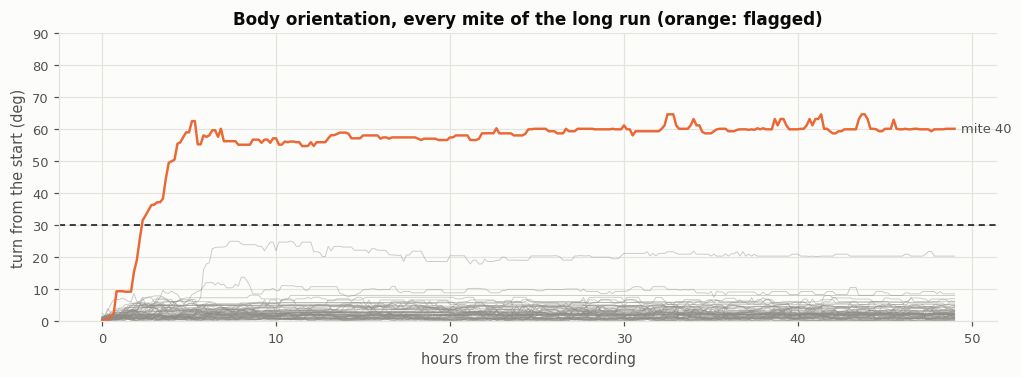

In [10]:
def body(image):
    # (orientation in degrees 0-180, long axis / short axis) of the dark blob under the image's centre
    grey = cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    _, dark = cv2.threshold(grey, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    count, labels = cv2.connectedComponents(dark)
    centre = labels[labels.shape[0] // 2 - 2:labels.shape[0] // 2 + 3, labels.shape[1] // 2 - 2:labels.shape[1] // 2 + 3]
    centre = centre[centre > 0]
    if not centre.size:
        return np.nan, np.nan
    ys, xs = np.nonzero(labels == np.bincount(centre).argmax())
    if len(xs) < 5:
        return np.nan, np.nan
    values, vectors = np.linalg.eigh(np.cov(np.vstack([xs, ys])))
    return np.degrees(np.arctan2(vectors[1, 1], vectors[0, 1])) % 180, np.sqrt(values[1] / max(values[0], 1e-9))


def turns(r):
    # (mites, recordings): smoothed angle from the first recordings, nan for a round mite
    out = np.full((len(r["ids"]), len(r["times"])), np.nan)
    for m, images in enumerate(r["images"]):
        found = np.array([body(image) for image in images])
        angle, long = found[:, 0], found[:, 1]
        if np.nanmedian(long) < 1.1:
            continue
        start = np.nanmedian(angle[:3])
        turn = np.abs((angle - start + 90) % 180 - 90)
        out[m] = pd.Series(turn).rolling(5, center=True, min_periods=1).median().to_numpy()
    return out


for r in runs.values():
    r["turn"] = turns(r)
TURN_LIMIT = 30.0   # degrees
turned = runs[LONG]["kept"] & ((runs[LONG]["turn"] > TURN_LIMIT).sum(axis=1) >= AWAY_COUNT)
dead_turns = runs[LONG]["turn"][dead & ~turned[:, None]]
print(f"dead mites of the long run, the turned ones left out: turn median {np.nanmedian(dead_turns):.1f} deg, 99.9% {np.nanpercentile(dead_turns, 99.9):.1f} deg, "
      f"largest {np.nanmax(dead_turns):.1f}; limit {TURN_LIMIT:g} deg; round mites left out: "
      + ", ".join(f"{n} {int(np.isnan(r['turn']).all(axis=1)[r['kept']].sum())}" for n, r in runs.items()))

rows = []
for name, r in runs.items():
    r["flag_turn"] = r["kept"] & ((r["turn"] > TURN_LIMIT).sum(axis=1) >= AWAY_COUNT)
    for m in np.flatnonzero(r["flag_turn"]):
        rows.append({"dataset": name, "mite": r["ids"][m], "zone": r["zones"][m],
                     "largest turn (deg)": np.nanmax(r["turn"][m]),
                     f"recordings > {TURN_LIMIT:g} deg": int((r["turn"][m] > TURN_LIMIT).sum()),
                     "first of them (h)": r["times"][np.argmax(r["turn"][m] > TURN_LIMIT)] / 60,
                     "also left its zone": bool(r["flag_across"][m])})
display(pd.DataFrame(rows).style.format(precision=1).hide(axis="index"))

run = runs[LONG]
hours = run["times"] / 60
fig, ax = plt.subplots(figsize=(11, 3.4))
for m in np.flatnonzero(run["kept"] & ~run["flag_turn"]):
    ax.plot(hours, run["turn"][m], color=GREY, linewidth=0.6, alpha=0.45)
for m in np.flatnonzero(run["flag_turn"]):
    ax.plot(hours, run["turn"][m], color=ORANGE, linewidth=1.6)
    ax.annotate(f"mite {run['ids'][m]}", (hours[-1], run["turn"][m, -1]), xytext=(4, 0), textcoords="offset points",
                fontsize=8.5, color=MUTED, va="center")
ax.axhline(TURN_LIMIT, color=INK, linewidth=1, linestyle=(0, (4, 3)))
ax.set(xlabel="hours from the first recording", ylabel="turn from the start (deg)", ylim=(0, 90),
       title=f"Body orientation, every mite of the long run (orange: flagged)")
plt.show()

### What the flagged mites look like

What the user would review: each flagged mite read from its recordings, 4× enlarged, its box plus 8 px in yellow. A mite flagged within a recording: frames of that recording. A mite flagged for leaving its zone: the first frame of recordings before and after it left.

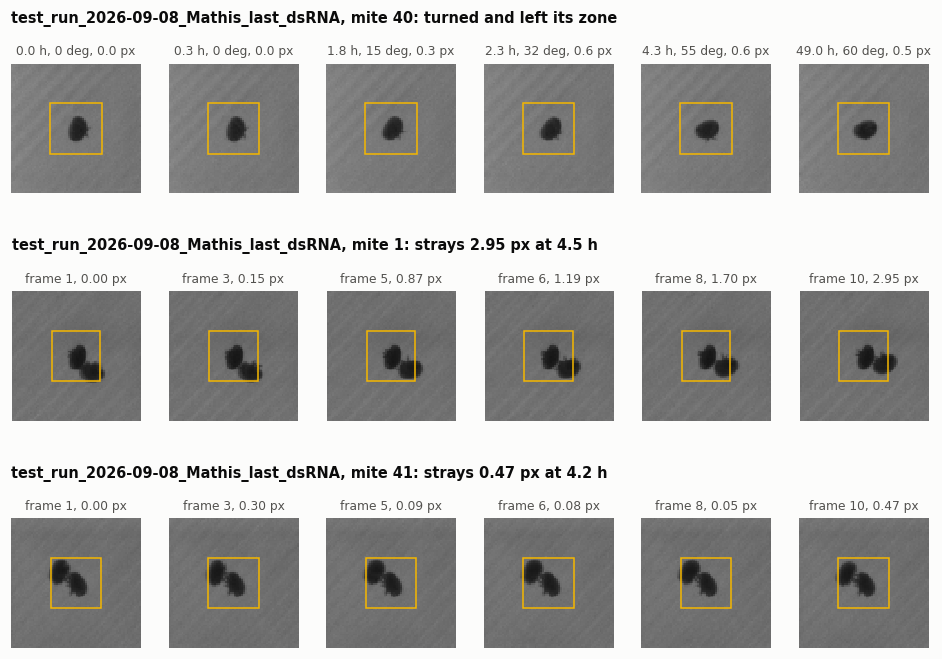

In [11]:
SIDE = 30   # pixels around the box shown


def crops(name, mite, recording, frames):
    summary = next(s for s in pipeline.list_calibration_datasets() if pipeline._read_dataset(
        s["id"], pipeline.CALIBRATION_LIBRARY)["name"] == name)
    data = pipeline._read_dataset(summary["id"], pipeline.CALIBRATION_LIBRARY)
    recordings_dir = pipeline._recordings_dir(data["data_dir"], pipeline.CALIBRATION_LIBRARY)
    if not recordings_dir.is_dir():
        recordings_dir = pipeline._dataset_dir(summary["id"], pipeline.CALIBRATION_LIBRARY) / pipeline.RECORDINGS_DIRNAME
    x1, y1, x2, y2 = pipeline.mite_boxes(data["mites"])[runs[name]["ids"][mite]]
    stack = DataLoader(recordings_dir, grayscale=False).load_recording_region(
        data["recordings"][recording]["name"], x1 - SIDE, y1 - SIDE, x2 + SIDE, y2 + SIDE)
    return [stack[f][..., ::-1] for f in frames], (SIDE - MARGIN, SIDE - MARGIN, x2 - x1 + 2 * MARGIN, y2 - y1 + 2 * MARGIN)


def strip(ax_row, name, mite, picks, caption):
    for ax, (recording, frame, label) in zip(ax_row, picks):
        (image,), (x, y, w, h) = crops(name, mite, recording, [frame])
        ax.imshow(image, interpolation="nearest")
        ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), w, h, fill=False, edgecolor="#f5b700", linewidth=1))
        ax.set_title(label, fontsize=8, color=MUTED, fontweight="normal")
        ax.axis("off")
    for ax in ax_row[len(picks):]:
        ax.axis("off")
    ax_row[0].annotate(caption, (0, 1.32), xycoords="axes fraction", fontsize=9.5, color=INK, fontweight="bold")


examples = []
for name, r in runs.items():
    hours_of = r["times"] / 60
    for m in np.flatnonzero(r["flag_across"] | r["flag_turn"]):
        # around the first recording flagged: from 3 before to 2 after, and the last
        first = int(np.argmax((r["turn"][m] > TURN_LIMIT) if r["flag_turn"][m] else (r["away"][m] > AWAY_LIMIT)))
        picks = sorted({0, max(0, first - 12), max(0, first - 3), first, min(first + 12, len(r["times"]) - 1),
                        len(r["times"]) - 1})
        why = " and ".join(w for w, f in (("turned", r["flag_turn"][m]), ("left its zone", r["flag_across"][m])) if f)
        examples.append((name, m, [(i, 0, f"{hours_of[i]:.1f} h, {np.nan_to_num(r['turn'][m, i]):.0f} deg, "
                                           f"{r['away'][m, i]:.1f} px") for i in picks],
                         f"{name}, mite {r['ids'][m]}: {why}"))
    worst = sorted(np.flatnonzero(r["flag_within"].any(axis=1) & ~r["flag_across"] & ~r["flag_turn"]),
                   key=lambda m: -r["stray"][m].max())
    for m in worst[:2]:
        at = int(np.argmax(r["stray"][m]))
        n_frames = r["within"].shape[2]
        frames = [int(f) for f in np.linspace(0, n_frames - 1, 6).round()]
        examples.append((name, m, [(at, f, f"frame {f + 1}, {np.hypot(*(r['within'][m, at, f, :2] - np.median(r['within'][:, at, f, :2], axis=0))):.2f} px")
                                   for f in frames],
                         f"{name}, mite {r['ids'][m]}: strays {r['stray'][m, at]:.2f} px at {r['times'][at] / 60:.1f} h"))

fig, axes = plt.subplots(len(examples), 6, figsize=(11, 2.3 * len(examples)), squeeze=False,
                         gridspec_kw={"hspace": 0.75, "wspace": 0.05})
for row, (name, m, picks, caption) in zip(axes, examples):
    strip(row, name, m, picks, caption)
plt.show()

### The mite that came by

The neighbour in mite 1's and mite 41's patches is no detected mite: the nearest detections are 73 px or more away, and all are still then. It is the detection marked *not a mite* in the ground truth. Its box is empty for most of the run because the mite walked off. It is tracked here from its box: each recording's first frame against the plate without it (the median of 10 recordings late in the run, after it has gone), the dark blob nearest to where it was last. Drawn on the first frame, with every detection's box (flagged ones in orange).

detection 12 (marked not a mite, zone 3): followed for 44 recordings, to 7.17 h; after that it is not seen moving again in this part of the plate


recording,hours,passes mite,distance (px),that mite's stray (px),flagged
25,4.00,49,14.60,0.32,True
26,4.17,41,11.35,0.47,True
27,4.33,55,22.46,0.11,False
28,4.50,1,11.58,2.95,True


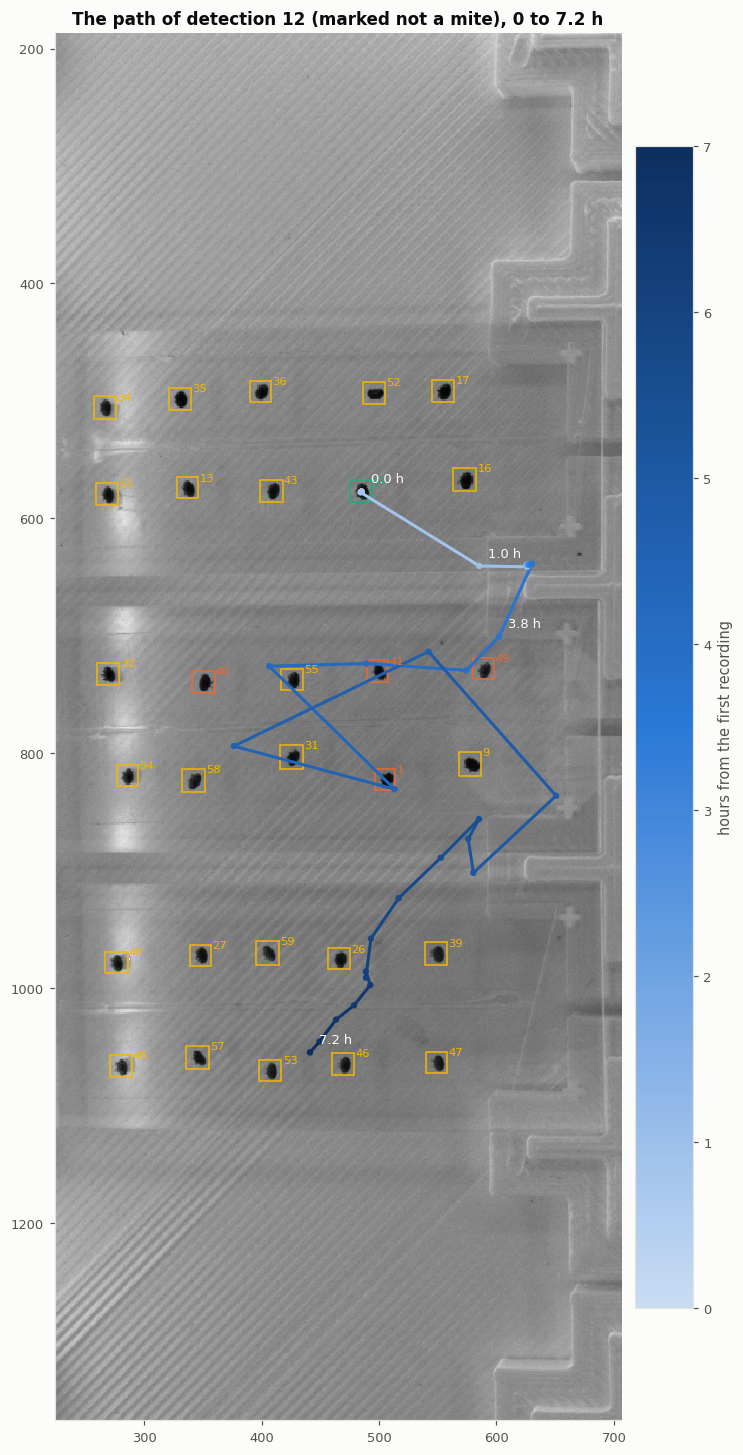

In [12]:
run = runs[LONG]
summary = next(s for s in pipeline.list_calibration_datasets() if s["id"].startswith(LONG))
data = pipeline._read_dataset(summary["id"], pipeline.CALIBRATION_LIBRARY)
recordings_dir = pipeline._recordings_dir(data["data_dir"], pipeline.CALIBRATION_LIBRARY)
if not recordings_dir.is_dir():
    recordings_dir = pipeline._dataset_dir(summary["id"], pipeline.CALIBRATION_LIBRARY) / pipeline.RECORDINGS_DIRNAME
loader = DataLoader(recordings_dir, grayscale=True)
names = [recording["name"] for recording in data["recordings"]]
boxes = pipeline.mite_boxes(data["mites"])
hours = run["times"] / 60
flagged_ids = {run["ids"][m] for m in np.flatnonzero(run["kept"]) if run["flag_within"][m].any() or run["flag_across"][m] or run["flag_turn"][m]}

for wanderer in [run["ids"][m] for m in np.flatnonzero(~run["kept"])]:
    zone = run["zones"][run["ids"].index(wanderer)]
    # its zone and the zones it can reach: the whole column of zones it is in, on the plate
    x0, y0, x1, y1 = 0, 0, data["image"]["width"], data["image"]["height"]
    centre = np.array([(boxes[wanderer][0] + boxes[wanderer][2]) / 2, (boxes[wanderer][1] + boxes[wanderer][3]) / 2])
    column = [z for z in data["zones"] if z["x1"] <= centre[0] <= z["x2"]]
    x0, y0 = min(z["x1"] for z in column) - 10, min(z["y1"] for z in column) - 10
    x1, y1 = max(z["x2"] for z in column) + 10, max(z["y2"] for z in column) + 10
    first = lambda r: loader.load_recording_region(names[r], x0, y0, x1, y1, step=1000)[0].astype(np.float32)
    background = np.median([first(r) for r in np.linspace(len(names) // 2, len(names) - 1, 10).astype(int)], axis=0)
    path, at = [], centre
    for r in range(len(names)):
        diff = cv2.GaussianBlur(background - first(r), (5, 5), 0)
        count, _, stats, centres = cv2.connectedComponentsWithStats((diff > 35).astype(np.uint8))
        blobs = [centres[i] + (x0, y0) for i in range(1, count) if stats[i, cv2.CC_STAT_AREA] > 40]
        if not blobs:
            break
        nearest = min(blobs, key=lambda b: np.hypot(*(b - at)))
        if np.hypot(*(nearest - at)) > 200:
            break
        at = nearest
        path.append((r, *at))
    path = np.array(path)
    last = int(path[-1, 0])
    print(f"detection {wanderer} (marked not a mite, zone {zone}): followed for {len(path)} recordings, "
          f"to {hours[last]:.2f} h; after that it is not seen moving again in this part of the plate")

    # where it passed the detected mites: within 25 px of a box's centre
    rows = []
    for k, (bx1, by1, bx2, by2) in boxes.items():
        if k == wanderer:
            continue
        distance = np.hypot(path[:, 1] - (bx1 + bx2) / 2, path[:, 2] - (by1 + by2) / 2)
        for index in np.flatnonzero(distance < 25):
            r = int(path[index, 0])
            m = run["ids"].index(k)
            rows.append({"recording": r + 1, "hours": hours[r], "passes mite": k, "distance (px)": distance[index],
                         "that mite's stray (px)": run["stray"][m, r], "flagged": bool(run["flag_within"][m, r])})
    display(pd.DataFrame(rows).sort_values("recording").style.format(precision=2).hide(axis="index"))

    image = loader.load_recording_region(names[0], x0, y0, x1, y1, step=1000)[0]
    fig, ax = plt.subplots(figsize=(8, 8 * (y1 - y0) / (x1 - x0)))
    ax.imshow(image, cmap="gray", extent=(x0, x1, y1, y0), interpolation="nearest")
    for k, (bx1, by1, bx2, by2) in boxes.items():
        if x0 <= bx1 and bx2 <= x1 and y0 <= by1 and by2 <= y1:
            colour = ORANGE if k in flagged_ids else "#f5b700" if k != wanderer else AQUA
            ax.add_patch(plt.Rectangle((bx1 - 3, by1 - 3), bx2 - bx1 + 6, by2 - by1 + 6, fill=False, edgecolor=colour,
                                       linewidth=1))
            ax.annotate(k, (bx2 + 4, by1), fontsize=7.5, color=colour)
    lines = LineCollection(np.stack([path[:-1, 1:], path[1:, 1:]], axis=1), cmap=TIME, linewidth=2)
    lines.set_array(hours[path[:-1, 0].astype(int)])
    ax.add_collection(lines)
    ax.scatter(path[:, 1], path[:, 2], s=10, c=hours[path[:, 0].astype(int)], cmap=TIME, zorder=3)
    for r, x, y in path[[0, 6, 23, -1]]:
        ax.annotate(f"{hours[int(r)]:.1f} h", (x, y), xytext=(6, 6), textcoords="offset points", fontsize=8.5,
                    color="#fcfcfb")
    ax.set(xlim=(x0, x1), ylim=(y1, y0), title=f"The path of detection {wanderer} (marked not a mite), "
                                               f"0 to {hours[last]:.1f} h")
    ax.grid(visible=False)
    fig.colorbar(lines, ax=ax, pad=0.02, shrink=0.7, label="hours from the first recording")
    plt.show()

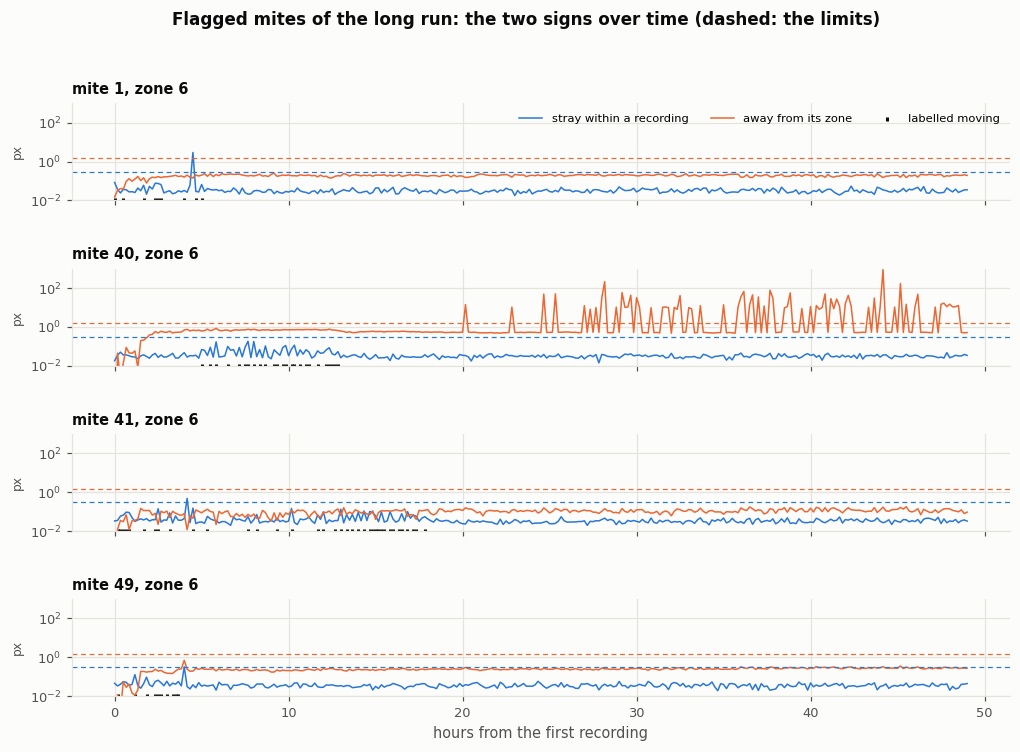

In [13]:
run = runs[LONG]
hours = run["times"] / 60
flagged = [m for m in np.flatnonzero(run["kept"]) if run["flag_within"][m].any() or run["flag_across"][m] or run["flag_turn"][m]]
fig, axes = plt.subplots(len(flagged), 1, figsize=(11, 1.6 * len(flagged) + 0.6), sharex=True, squeeze=False,
                         gridspec_kw={"hspace": 0.7})
for ax, m in zip(axes[:, 0], flagged):
    ax.plot(hours, run["stray"][m], color=BLUE, linewidth=1, label="stray within a recording")
    ax.plot(hours, run["away"][m], color=ORANGE, linewidth=1, label="away from its zone")
    ax.axhline(STRAY_LIMIT, color=BLUE, linewidth=0.8, linestyle=(0, (4, 3)))
    ax.axhline(AWAY_LIMIT, color=ORANGE, linewidth=0.8, linestyle=(0, (4, 3)))
    ax.scatter(hours[run["moving"][m]], np.full(run["moving"][m].sum(), 0.01), s=10, color=INK, marker="|",
               label="labelled moving")
    ax.set_yscale("log")
    ax.set_ylim(0.01, 1000)
    ax.set_ylabel("px", fontsize=8)
    ax.set_title(f"mite {run['ids'][m]}, zone {run['zones'][m]}", fontsize=9.5, loc="left")
axes[0, 0].legend(loc="upper right", ncols=3, fontsize=7.5)
axes[-1, 0].set_xlabel("hours from the first recording")
fig.suptitle(f"Flagged mites of the long run: the two signs over time (dashed: the limits)", fontsize=11,
             fontweight="bold", color=INK, y=1.0)
plt.show()

## 5. What the change to the code would be

Not made yet; the change this report points to:

- `PlateStabilizer.shifts()` returns each mite's own shifts next to the plate's median (it measures them already and throws them away).
- `PlateStabilizer.cut()` moves each mite's patch back by its own shift. In a recording where that strays more than `STRAY_LIMIT` from the plate's, it falls back to the plate's shift, and the mite and recording are flagged.
- Across recordings, a mite is flagged if it turns by more than `TURN_LIMIT` or sits more than `AWAY_LIMIT` from its zone's median, in `AWAY_COUNT` recordings. This needs each mite's mean image in each recording kept (as `RecordingChange` does): its body's orientation, and its registration against its first image.
- The flags go to the result pages for review, next to the corrections that exist already (*not a mite*, a call corrected by hand), with the pictures above.